## Importing libraries

In [2]:
#Import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## loading datasets

In [4]:
historical = pd.read_csv("cyberbullying_tweets train.csv")
recent = pd.read_excel("CyberbullyX-63K test.xlsx")

In [5]:
historical.head()

,tweet_text,cyberbullying_type
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying


In [6]:
recent.head()

,tweet_id,date,lang,text,final_label
0,1278039274991075329,2020-06-30 18:54:42+00:00,en,Say this to everyone who thinks that it’s ok t...,1
1,1277913148163420165,2020-06-30 10:33:31+00:00,en,One word for this chutiya Guswami 😂 #ArnabGosw...,1
2,1277821777154990080,2020-06-30 04:30:27+00:00,en,Joined Tribe Membership 😊 @BewakoofBrands #bew...,0
3,1277821301806125057,2020-06-30 04:28:33+00:00,hi,Ye hutiyapa he. NO ITS THERE. YE SARE MILKE HU...,1
4,1277649641165611009,2020-06-29 17:06:26+00:00,hi,Chutiya bus andhbhakt hi ban sakta Yahan dikh...,1


The historical dataset contains tweet text and categorical cyberbullying labels, and is used to train the machine learning models on older language patterns (approximately 2018–2020). The recent dataset contains Twitter/X posts collected between January 2020 and May 2026, together with additional metadata and binary labels, and is used to evaluate model performance on more recent language. Using these two datasets enables the study to assess how well traditional machine learning models generalize to evolving cyberbullying language over time.

## Class Distribution Analysis

In [9]:
print("Historical Dataset Shape:", historical.shape)
print("Recent Dataset Shape:", recent.shape)

print("\nHistorical Dataset Columns:")
print(historical.columns)
print("Recent Dataset Columns:")
print(recent.columns)

Historical Dataset Shape: (47692, 2)
Recent Dataset Shape: (63145, 5)

Historical Dataset Columns:
Index(['tweet_text', 'cyberbullying_type'], dtype='object')
Recent Dataset Columns:
Index(['tweet_id', 'date', 'lang', 'text', 'final_label'], dtype='object')


The historical dataset consists of 47,692 tweets with two variables: tweet text and the cyberbullying category. The recent dataset contains 63,145 tweets and includes additional metadata such as tweet ID, date, language, and binary cyberbullying labels. The larger size and richer structure of the recent dataset make it suitable for evaluating model performance under more recent and diverse language conditions.

## Datasets Information

In [12]:
historical.info()
recent.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47692 entries, 0 to 47691
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   tweet_text          47692 non-null  object
 1   cyberbullying_type  47692 non-null  object
dtypes: object(2)
memory usage: 745.3+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63145 entries, 0 to 63144
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   tweet_id     63145 non-null  int64 
 1   date         63145 non-null  object
 2   lang         63145 non-null  object
 3   text         63145 non-null  object
 4   final_label  63145 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 2.4+ MB


The recent dataset contains tweet text together with additional metadata, including tweet identifiers, posting dates, language information, and binary cyberbullying labels. All columns are complete with no missing values, providing a reliable dataset for evaluating model performance on more recent online language.

## check and remove duplicates

In [15]:
print(historical.duplicated().sum())

36


In [16]:
print(recent.duplicated().sum())

0


In [17]:
historical = historical.drop_duplicates()
print(historical.duplicated().sum())

0


The historical dataset contained 36 duplicate records, representing approximately 0.08% of the data. These duplicates were removed to prevent repeated observations from influencing model training and to improve the overall quality of the dataset.

## label distribution

In [20]:
historical["cyberbullying_type"].value_counts()

cyberbullying_type
religion               7997
age                    7992
ethnicity              7959
gender                 7948
not_cyberbullying      7937
other_cyberbullying    7823
Name: count, dtype: int64

In [21]:
recent["final_label"].value_counts()

final_label
0    32940
1    30205
Name: count, dtype: int64

The historical dataset is initially balanced across its six original categories; however, these categories will be combined into a binary classification problem during preprocessing, resulting in a larger cyberbullying class than the non-cyberbullying class. In contrast, the recent dataset is already relatively balanced between cyberbullying and non-cyberbullying labels. Class imbalance in the historical dataset may bias the models toward predicting the majority class, potentially reducing their ability to correctly identify non-cyberbullying tweets. To address this, model performance will be evaluated using precision, recall, F1-score, and the confusion matrix rather than relying solely on accuracy. If the imbalance is found to negatively affect performance, techniques such as class weighting or SMOTE will be investigated and their impact compared with the baseline models.


## Visualize the label distribution

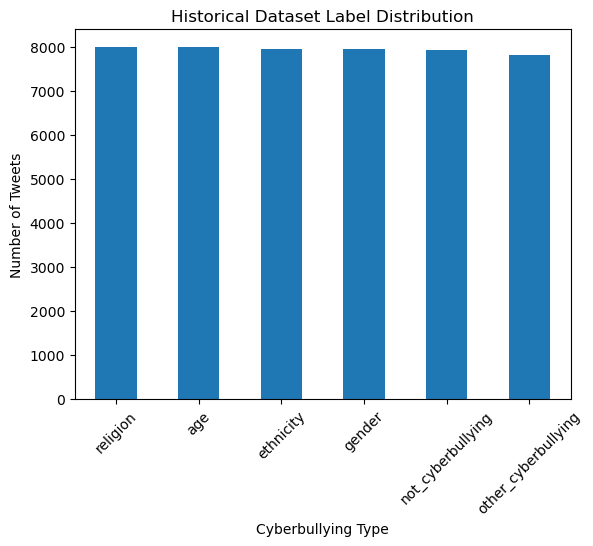

In [24]:
import matplotlib.pyplot as plt

historical["cyberbullying_type"].value_counts().plot(kind="bar")
plt.title("Historical Dataset Label Distribution")
plt.xlabel("Cyberbullying Type")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)
plt.show()

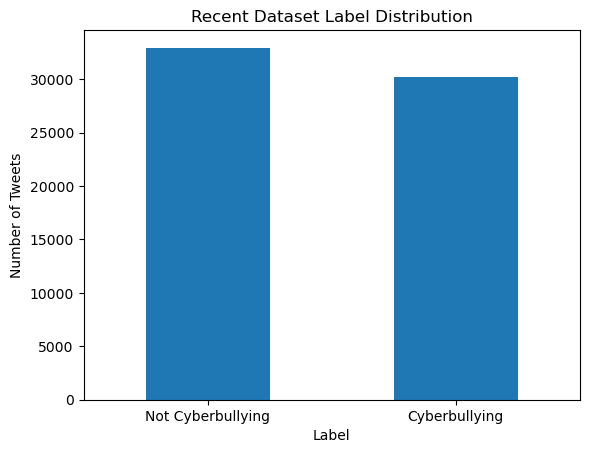

In [25]:
recent["final_label"].value_counts().plot(kind="bar")
plt.title("Recent Dataset Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Tweets")
plt.xticks([0, 1], ["Not Cyberbullying", "Cyberbullying"], rotation=0)
plt.show()

## Data preparation

In [27]:
recent["lang"].value_counts()

lang
hi     38304
en     24683
et       121
tl         9
eu         5
ht         5
fr         4
in         4
nl         4
es         2
pt         1
de         1
it         1
und        1
Name: count, dtype: int64

In [28]:
historical_original = historical.copy()
recent_original = recent.copy()

In [29]:
recent = recent[recent["lang"] == "en"]

In [30]:
recent.shape

(24683, 5)

In [31]:
recent["final_label"].value_counts()

final_label
0    18736
1     5947
Name: count, dtype: int64

In [32]:
historical["tweet_text"].sample(5, random_state=42)

14204                     Yup there still hot blondes #mkr
37790    alissa violet rlly said "it's everyday bro w t...
5460     Ever get #bullied for being fat? Porky gets he...
18629    @FarooqSumar @NafeezAhmed @MaxBlumenthal Wrong...
13110    RT @thetrudz: And, it is comical for Emma to m...
Name: tweet_text, dtype: object

In [33]:
recent["text"].sample(5, random_state=42)

17261    Me, i'm a whore member of the gooning for Vark...
58841    NO THEY WEREN'T HIS ASS SHOULD BE IN JAIL http...
62774    unexpected bestie meetups💀&gt;&gt;&gt; https:/...
60719    This is the second time a foreigner played Jos...
21442    I was banned from CB yesterday after 10+ years...
Name: text, dtype: object

The recent dataset originally contained tweets in multiple languages. To ensure a fair comparison with the historical English dataset, only English-language tweets were retained for analysis. This controlled for language as a confounding variable and allowed the study to focus on the impact of linguistic evolution over time on cyberbullying detection

In [35]:
historical.rename(columns={
    "tweet_text": "text",
    "cyberbullying_type": "label"
}, inplace=True)

In [36]:
recent = recent[["text", "final_label"]]

recent.rename(columns={
    "final_label": "label"
}, inplace=True)

In [37]:
historical.head()

,text,label
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying


In [38]:
recent.head()

,text,label
0,Say this to everyone who thinks that it’s ok t...,1
1,One word for this chutiya Guswami 😂 #ArnabGosw...,1
2,Joined Tribe Membership 😊 @BewakoofBrands #bew...,0
5,#PUBGMOBILE #PUBG is a south Korean app not C...,1
6,I will purchase d mobile.but technical problem...,0


In [39]:
recent.reset_index(drop=True, inplace=True)
recent.head()

,text,label
0,Say this to everyone who thinks that it’s ok t...,1
1,One word for this chutiya Guswami 😂 #ArnabGosw...,1
2,Joined Tribe Membership 😊 @BewakoofBrands #bew...,0
3,#PUBGMOBILE #PUBG is a south Korean app not C...,1
4,I will purchase d mobile.but technical problem...,0


In [40]:
historical["label"] = historical["label"].replace({
    "not_cyberbullying": 0,
    "religion": 1,
    "age": 1,
    "gender": 1,
    "ethnicity": 1,
    "other_cyberbullying": 1
})

historical["label"].value_counts()

label
1    39719
0     7937
Name: count, dtype: int64

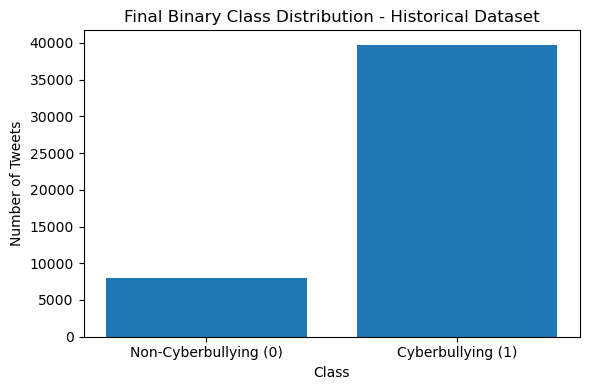

In [41]:
label_counts = historical["label"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    ["Non-Cyberbullying (0)", "Cyberbullying (1)"],
    label_counts.values
)

plt.title("Final Binary Class Distribution - Historical Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

This graph shows the final binary class distribution in my historical dataset after preprocessing and label conversion. It shows a substantial imbalance between the two classes, with significantly more cyberbullying samples than non-cyberbullying samples. When I observed this imbalance during implementation, I recognized that it could cause the models to favour the majority class and potentially perform poorly when identifying the minority class. Although class weighting was not included in my original proposal, I decided to incorporate it as a methodological adjustment based on the characteristics of the actual dataset. I will use balanced class weights during model training while keeping the original data unchanged, and then compare model performance using metrics such as precision, recall and F1-score

In [43]:
historical.info()

recent.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47656 entries, 0 to 47691
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    47656 non-null  object
 1   label   47656 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24683 entries, 0 to 24682
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    24683 non-null  object
 1   label   24683 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 385.8+ KB


## Text preprocessing

In [45]:
# Create a copy of the original text
historical["clean_text"] = historical["text"]
recent["clean_text"] = recent["text"]

In [46]:
historical[["text", "clean_text"]].head()

,text,clean_text
0,"In other words #katandandre, your food was cra...","In other words #katandandre, your food was cra..."
1,Why is #aussietv so white? #MKR #theblock #ImA...,Why is #aussietv so white? #MKR #theblock #ImA...
2,@XochitlSuckkks a classy whore? Or more red ve...,@XochitlSuckkks a classy whore? Or more red ve...
3,"@Jason_Gio meh. :P thanks for the heads up, b...","@Jason_Gio meh. :P thanks for the heads up, b..."
4,@RudhoeEnglish This is an ISIS account pretend...,@RudhoeEnglish This is an ISIS account pretend...


In [47]:
recent[["text", "clean_text"]].head()

,text,clean_text
0,Say this to everyone who thinks that it’s ok t...,Say this to everyone who thinks that it’s ok t...
1,One word for this chutiya Guswami 😂 #ArnabGosw...,One word for this chutiya Guswami 😂 #ArnabGosw...
2,Joined Tribe Membership 😊 @BewakoofBrands #bew...,Joined Tribe Membership 😊 @BewakoofBrands #bew...
3,#PUBGMOBILE #PUBG is a south Korean app not C...,#PUBGMOBILE #PUBG is a south Korean app not C...
4,I will purchase d mobile.but technical problem...,I will purchase d mobile.but technical problem...


In [48]:
# Convert text to lowercase
historical["clean_text"] = historical["clean_text"].str.lower()
recent["clean_text"] = recent["clean_text"].str.lower()

In [49]:
historical["clean_text"].head()

0    in other words #katandandre, your food was cra...
1    why is #aussietv so white? #mkr #theblock #ima...
2    @xochitlsuckkks a classy whore? or more red ve...
3    @jason_gio meh. :p  thanks for the heads up, b...
4    @rudhoeenglish this is an isis account pretend...
Name: clean_text, dtype: object

In [50]:
recent["clean_text"].head()

0    say this to everyone who thinks that it’s ok t...
1    one word for this chutiya guswami 😂 #arnabgosw...
2    joined tribe membership 😊 @bewakoofbrands #bew...
3    #pubgmobile  #pubg is a south korean app not c...
4    i will purchase d mobile.but technical problem...
Name: clean_text, dtype: object

In [51]:
import re

In [52]:
def remove_urls(text):
    return re.sub(r"http\S+|www\S+|https\S+", "", text)

In [53]:
historical["clean_text"] = historical["clean_text"].apply(remove_urls)
recent["clean_text"] = recent["clean_text"].apply(remove_urls)

In [54]:
recent["clean_text"].sample(5, random_state=42)

13884    me, i'm a whore member of the gooning for vark...
20379           no they weren't his ass should be in jail 
24312              unexpected bestie meetups💀&gt;&gt;&gt; 
22257    this is the second time a foreigner played jos...
16046    i was banned from cb yesterday after 10+ years...
Name: clean_text, dtype: object

In [55]:
def remove_mentions(text):
    return re.sub(r"@\w+", "", text)

In [56]:
historical["clean_text"] = historical["clean_text"].apply(remove_mentions)
recent["clean_text"] = recent["clean_text"].apply(remove_mentions)

In [57]:
def remove_hashtag_symbol(text):
    return re.sub(r"#", "", text)

In [58]:
historical["clean_text"] = historical["clean_text"].apply(remove_hashtag_symbol)
recent["clean_text"] = recent["clean_text"].apply(remove_hashtag_symbol)

In [59]:
import string

In [60]:
def remove_punctuation(text):
    return text.translate(str.maketrans("", "", string.punctuation))

In [61]:
historical["clean_text"] = historical["clean_text"].apply(remove_punctuation)
recent["clean_text"] = recent["clean_text"].apply(remove_punctuation)

In [62]:
def remove_numbers(text):
    return re.sub(r"\d+", "", text)

In [63]:
historical["clean_text"] = historical["clean_text"].apply(remove_numbers)
recent["clean_text"] = recent["clean_text"].apply(remove_numbers)

In [64]:
def remove_extra_spaces(text):
    return re.sub(r"\s+", " ", text).strip()

In [65]:
historical["clean_text"] = historical["clean_text"].apply(remove_extra_spaces)
recent["clean_text"] = recent["clean_text"].apply(remove_extra_spaces)

In [66]:
historical[["text", "clean_text"]].sample(5, random_state=42)

,text,clean_text
14204,Yup there still hot blondes #mkr,yup there still hot blondes mkr
37790,"alissa violet rlly said ""it's everyday bro w t...",alissa violet rlly said its everyday bro w the...
5460,Ever get #bullied for being fat? Porky gets he...,ever get bullied for being fat porky gets her ...
18629,@FarooqSumar @NafeezAhmed @MaxBlumenthal Wrong...,wrong again islam nazism and muslim murderers ...
13110,"RT @thetrudz: And, it is comical for Emma to m...",rt and it is comical for emma to mention male ...


In [67]:
recent[["text", "clean_text"]].sample(5, random_state=42)

,text,clean_text
13884,"Me, i'm a whore member of the gooning for Vark...",me im a whore member of the gooning for varka ...
20379,NO THEY WEREN'T HIS ASS SHOULD BE IN JAIL http...,no they werent his ass should be in jail
24312,unexpected bestie meetups💀&gt;&gt;&gt; https:/...,unexpected bestie meetups💀gtgtgt
22257,This is the second time a foreigner played Jos...,this is the second time a foreigner played jos...
16046,I was banned from CB yesterday after 10+ years...,i was banned from cb yesterday after years i d...


In [68]:
def remove_rt(text):
    return re.sub(r"\brt\b", "", text)

In [69]:
historical["clean_text"] = historical["clean_text"].apply(remove_rt)
recent["clean_text"] = recent["clean_text"].apply(remove_rt)

In [70]:
import html

historical["clean_text"] = historical["clean_text"].apply(html.unescape)
recent["clean_text"] = recent["clean_text"].apply(html.unescape)

In [71]:
def remove_emojis(text):
    emoji_pattern = re.compile(
        "["
        u"\U0001F600-\U0001F64F"
        u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF"
        u"\U0001F1E0-\U0001F1FF"
        u"\U00002700-\U000027BF"
        u"\U000024C2-\U0001F251"
        "]+",
        flags=re.UNICODE,
    )
    return emoji_pattern.sub("", text)

In [72]:
historical["clean_text"] = historical["clean_text"].apply(remove_emojis)
recent["clean_text"] = recent["clean_text"].apply(remove_emojis)

In [73]:
historical["clean_text"] = historical["clean_text"].str.replace(r"\s+", " ", regex=True).str.strip()
recent["clean_text"] = recent["clean_text"].str.replace(r"\s+", " ", regex=True).str.strip()

In [74]:
historical[["clean_text"]].sample(10, random_state=42)

,clean_text
14204,yup there still hot blondes mkr
37790,alissa violet rlly said its everyday bro w the...
5460,ever get bullied for being fat porky gets her ...
18629,wrong again islam nazism and muslim murderers ...
13110,and it is comical for emma to mention male gaz...
20284,why would i care about the opinion of a guy wh...
13275,its so saddening that families will hide child...
16528,any body saying rss a terrorist organisation h...
37329,its funny to see my yr old brother get bullied...
40941,whitepower fuck obama dumb ass nigger


In [75]:
recent[["clean_text"]].sample(10, random_state=42)

,clean_text
13884,me im a whore member of the gooning for varka ...
20379,no they werent his ass should be in jail
24312,unexpected bestie meetupsgtgtgt
22257,this is the second time a foreigner played jos...
16046,i was banned from cb yesterday after years i d...
17785,he does this every time and people keep fallin...
5117,ab deaf dumb
11895,he cant eat with his left hand because thats w...
11941,take your ignorant opinions and gtfo these kid...
10163,i am going to bed just wrote a bad ass line fo...


In [76]:
historical["clean_text"] = historical["clean_text"].str.replace("gtgtgt", "", regex=False)
recent["clean_text"] = recent["clean_text"].str.replace("gtgtgt", "", regex=False)

## Tokenization

In [78]:
import nltk

nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [79]:
from nltk.tokenize import word_tokenize

In [80]:
historical["tokens"] = historical["clean_text"].apply(word_tokenize)
recent["tokens"] = recent["clean_text"].apply(word_tokenize)

In [81]:
historical[["clean_text", "tokens"]].sample(5, random_state=42)

,clean_text,tokens
14204,yup there still hot blondes mkr,"[yup, there, still, hot, blondes, mkr]"
37790,alissa violet rlly said its everyday bro w the...,"[alissa, violet, rlly, said, its, everyday, br..."
5460,ever get bullied for being fat porky gets her ...,"[ever, get, bullied, for, being, fat, porky, g..."
18629,wrong again islam nazism and muslim murderers ...,"[wrong, again, islam, nazism, and, muslim, mur..."
13110,and it is comical for emma to mention male gaz...,"[and, it, is, comical, for, emma, to, mention,..."


In [82]:
recent[["clean_text", "tokens"]].sample(5, random_state=42)

,clean_text,tokens
13884,me im a whore member of the gooning for varka ...,"[me, im, a, whore, member, of, the, gooning, f..."
20379,no they werent his ass should be in jail,"[no, they, werent, his, ass, should, be, in, j..."
24312,unexpected bestie meetups,"[unexpected, bestie, meetups]"
22257,this is the second time a foreigner played jos...,"[this, is, the, second, time, a, foreigner, pl..."
16046,i was banned from cb yesterday after years i d...,"[i, was, banned, from, cb, yesterday, after, y..."


In [83]:
type(historical["tokens"].iloc[0])

list

In [84]:
type(historical["tokens"].iloc[0][0])

str

In [85]:
from nltk.corpus import stopwords

In [86]:
stop_words = set(stopwords.words("english"))

In [87]:
negation_words = {"not", "no", "nor", "never"}
stop_words = stop_words - negation_words

In [88]:
historical["tokens"] = historical["tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

recent["tokens"] = recent["tokens"].apply(
    lambda words: [word for word in words if word not in stop_words]
)

In [89]:
historical[["clean_text", "tokens"]].sample(5, random_state=42)

,clean_text,tokens
14204,yup there still hot blondes mkr,"[yup, still, hot, blondes, mkr]"
37790,alissa violet rlly said its everyday bro w the...,"[alissa, violet, rlly, said, everyday, bro, w,..."
5460,ever get bullied for being fat porky gets her ...,"[ever, get, bullied, fat, porky, gets, revenge]"
18629,wrong again islam nazism and muslim murderers ...,"[wrong, islam, nazism, muslim, murderers, exte..."
13110,and it is comical for emma to mention male gaz...,"[comical, emma, mention, male, gaze, bey, spee..."


In [90]:
recent[["clean_text", "tokens"]].sample(5, random_state=42)

,clean_text,tokens
13884,me im a whore member of the gooning for varka ...,"[im, whore, member, gooning, varka, fandom, yes]"
20379,no they werent his ass should be in jail,"[no, werent, ass, jail]"
24312,unexpected bestie meetups,"[unexpected, bestie, meetups]"
22257,this is the second time a foreigner played jos...,"[second, time, foreigner, played, josephine, b..."
16046,i was banned from cb yesterday after years i d...,"[banned, cb, yesterday, years, dont, know, yet..."


Text preprocessing was performed to clean and standardize the tweet data before feature extraction and model training. Social media text often contains noise such as URLs, user mentions, hashtags, punctuation, emojis, and inconsistent capitalization, which can negatively affect model performance. The preprocessing pipeline included converting text to lowercase, removing URLs, mentions, punctuation, numbers, and unnecessary whitespace, while preserving meaningful textual content. The cleaned text was then prepared for Natural Language Processing (NLP) tasks, including tokenization, stopword removal, lemmatization, and TF-IDF feature extraction, to produce a consistent and informative representation of the tweets for machine learning.

Stopword removal is performed to eliminate common words that occur frequently but contribute little to distinguishing cyberbullying from non-cyberbullying content, such as the, is, and, and for. To preserve contextual meaning, negation words such as not, no, nor, and never are retained, as they can significantly alter the meaning of a sentence and influence the classification outcome.

## Lemmatization

In [94]:
from nltk.stem import WordNetLemmatizer

In [95]:
lemmatizer = WordNetLemmatizer()

In [96]:
historical["tokens"] = historical["tokens"].apply(
    lambda words: [lemmatizer.lemmatize(word) for word in words]
)

recent["tokens"] = recent["tokens"].apply(
    lambda words: [lemmatizer.lemmatize(word) for word in words]
)

In [97]:
historical[["tokens"]].sample(5, random_state=42)

,tokens
14204,"[yup, still, hot, blonde, mkr]"
37790,"[alissa, violet, rlly, said, everyday, bro, w,..."
5460,"[ever, get, bullied, fat, porky, get, revenge]"
18629,"[wrong, islam, nazism, muslim, murderer, exter..."
13110,"[comical, emma, mention, male, gaze, bey, spee..."


In [98]:
recent[["tokens"]].sample(5, random_state=42)

,tokens
13884,"[im, whore, member, gooning, varka, fandom, yes]"
20379,"[no, werent, as, jail]"
24312,"[unexpected, bestie, meetups]"
22257,"[second, time, foreigner, played, josephine, b..."
16046,"[banned, cb, yesterday, year, dont, know, yet,..."


## Join the tokens

In [100]:
historical["processed_text"] = historical["tokens"].apply(lambda words: " ".join(words))

recent["processed_text"] = recent["tokens"].apply(lambda words: " ".join(words))

In [101]:
historical[["clean_text", "processed_text"]].sample(5, random_state=42)

,clean_text,processed_text
14204,yup there still hot blondes mkr,yup still hot blonde mkr
37790,alissa violet rlly said its everyday bro w the...,alissa violet rlly said everyday bro w bully f...
5460,ever get bullied for being fat porky gets her ...,ever get bullied fat porky get revenge
18629,wrong again islam nazism and muslim murderers ...,wrong islam nazism muslim murderer exterminate...
13110,and it is comical for emma to mention male gaz...,comical emma mention male gaze bey speech cent...


In [102]:
recent[["clean_text", "processed_text"]].sample(5, random_state=42)

,clean_text,processed_text
13884,me im a whore member of the gooning for varka ...,im whore member gooning varka fandom yes
20379,no they werent his ass should be in jail,no werent as jail
24312,unexpected bestie meetups,unexpected bestie meetups
22257,this is the second time a foreigner played jos...,second time foreigner played josephine baker b...
16046,i was banned from cb yesterday after years i d...,banned cb yesterday year dont know yet think p...


After tokenization and lemmatization, the processed tokens were joined back into complete text strings. Although the text had been transformed during preprocessing, feature extraction techniques such as TF-IDF require textual input rather than lists of tokens. This step produced a final cleaned text representation that retained the essential linguistic information while ensuring compatibility with the machine learning pipeline.

## Checking for punctuations

In [105]:
print(historical["tokens"].head())
print(recent["tokens"].head())

0         [word, katandandre, food, crapilicious, mkr]
1    [aussietv, white, mkr, theblock, imacelebritya...
2                [classy, whore, red, velvet, cupcake]
3    [meh, p, thanks, head, not, concerned, another...
4    [isi, account, pretending, kurdish, account, l...
Name: tokens, dtype: object
0    [say, everyone, think, ’, ok, judge, anyone, u...
1          [one, word, chutiya, guswami, arnabgoswami]
2    [joined, tribe, membership, bewakoof, tribemem...
3    [pubgmobile, pubg, south, korean, app, not, ch...
4    [purchase, mobilebut, technical, problem, k, k...
Name: tokens, dtype: object


In [106]:
from collections import Counter

historical_word_counts = Counter(
    word
    for tokens in historical["tokens"]
    for word in tokens
)

recent_word_counts = Counter(
    word
    for tokens in recent["tokens"]
    for word in tokens
)

In [107]:
print([word for word, count in historical_word_counts.most_common(30)])

['school', '’', 'not', 'fuck', 'like', 'nigger', 'girl', 'joke', 'u', 'dumb', 'bully', 'high', 'people', 'muslim', 'bullied', 'gay', 'rape', 'one', 'im', 'no', 'idiot', 'dont', 'woman', 'get', '“', 'black', '”', 'as', 'mkr', 'amp']


After inspecting the tokenized data and the most frequent terms, I observed that some punctuation-only characters, such as ’, “, and ”, were still present as individual tokens. This means that these characters could be counted as words in the frequency analysis, which would make the word-frequency results less accurate. I therefore identified these punctuation-only tokens as an issue in the preprocessing stage and will remove them from the token lists before generating the final word-frequency graphs. This ensures that the analysis represents actual words rather than standalone punctuation symbols.

In [109]:
# Remove punctuation-only tokens from both datasets

import string

def remove_punctuation_tokens(tokens):
    return [
        word for word in tokens
        if not all(char in string.punctuation or char in "’“”" for char in word)
    ]

historical["tokens"] = historical["tokens"].apply(remove_punctuation_tokens)
recent["tokens"] = recent["tokens"].apply(remove_punctuation_tokens)

In [110]:
# Recreate processed_text after removing punctuation-only tokens

historical["processed_text"] = historical["tokens"].apply(
    lambda words: " ".join(words)
)

recent["processed_text"] = recent["tokens"].apply(
    lambda words: " ".join(words)
)

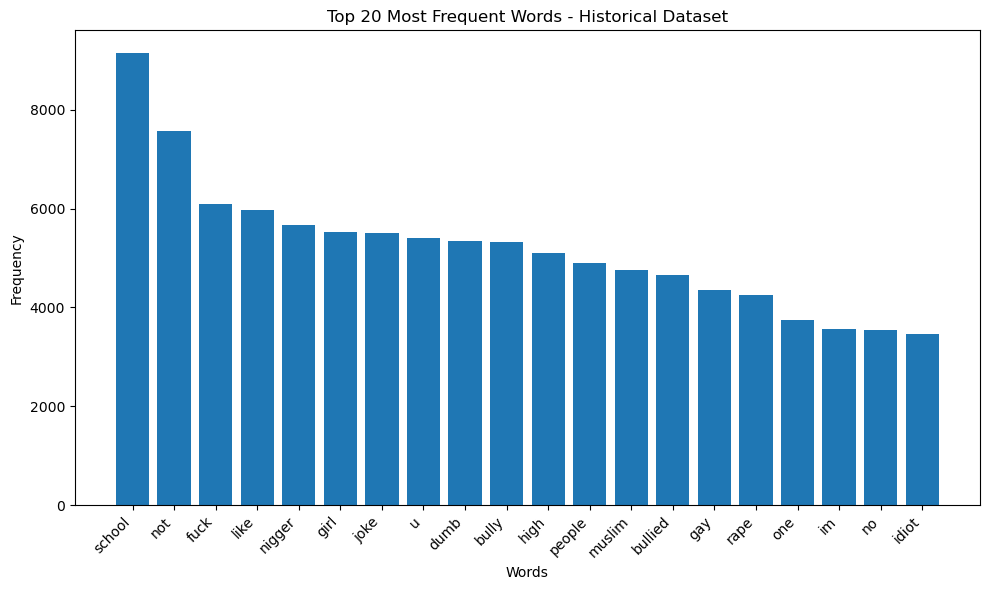

In [111]:
from collections import Counter
import matplotlib.pyplot as plt

# Historical dataset
historical_word_counts = Counter(
    word
    for tokens in historical["tokens"]
    for word in tokens
)

historical_top20 = historical_word_counts.most_common(20)

words = [word for word, count in historical_top20]
counts = [count for word, count in historical_top20]

plt.figure(figsize=(10, 6))
plt.bar(words, counts)
plt.title("Top 20 Most Frequent Words - Historical Dataset")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

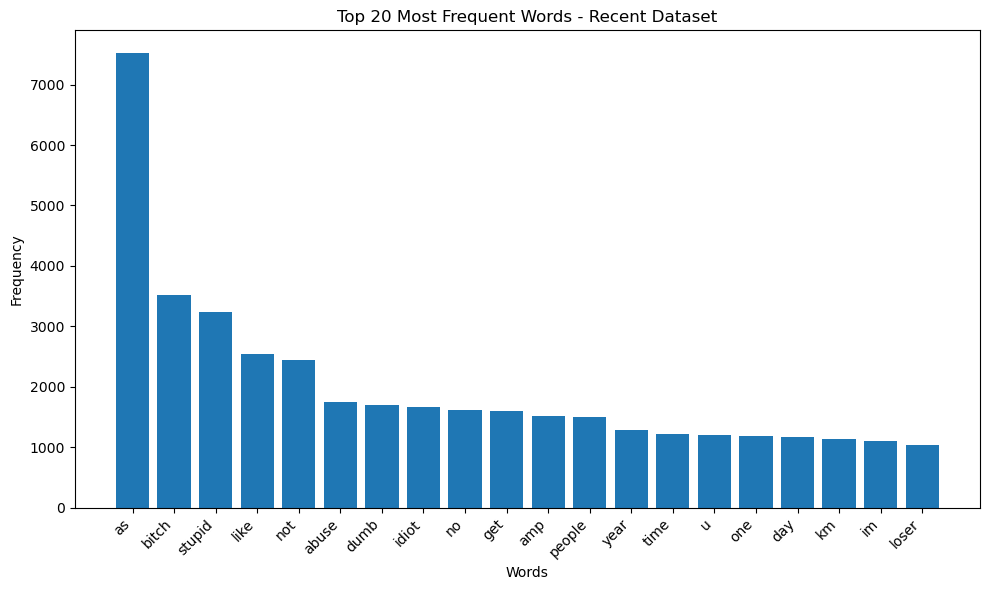

In [112]:
# Recent dataset
recent_word_counts = Counter(
    word
    for tokens in recent["tokens"]
    for word in tokens
)

recent_top20 = recent_word_counts.most_common(20)

words = [word for word, count in recent_top20]
counts = [count for word, count in recent_top20]

plt.figure(figsize=(10, 6))
plt.bar(words, counts)
plt.title("Top 20 Most Frequent Words - Recent Dataset")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The frequency distributions show differences in the most common terms between the historical and recent datasets. Although some terms occur frequently in both datasets, the ranking and frequency of several terms differ considerably. This provides an initial indication that the language characteristics of the datasets may have changed over time. These observations motivate the later evaluation of models trained on historical data against the recent dataset.

## Final checks and touch ups

In [115]:
print("Empty clean_text:", (historical["clean_text"].str.strip() == "").sum())
print("Empty processed_text:", (historical["processed_text"].str.strip() == "").sum())
print("Empty tokens:", (historical["tokens"].apply(len) == 0).sum())

Empty clean_text: 295
Empty processed_text: 358
Empty tokens: 358


In [116]:
historical = historical[historical["processed_text"].str.strip() != ""].copy()

In [117]:
print("New shape:", historical.shape)

print("Empty processed_text:",
      (historical["processed_text"].str.strip() == "").sum())

print("Empty tokens:",
      (historical["tokens"].apply(len) == 0).sum())

New shape: (47298, 5)
Empty processed_text: 0
Empty tokens: 0


In [118]:
print(historical.shape)
print(historical.isna().sum())

print("Empty processed_text:",
      (historical["processed_text"].str.strip() == "").sum())

print("Empty tokens:",
      (historical["tokens"].apply(len) == 0).sum())

(47298, 5)
text              0
label             0
clean_text        0
tokens            0
processed_text    0
dtype: int64
Empty processed_text: 0
Empty tokens: 0


In [119]:
print("HISTORICAL DATASET")
print("Shape:", historical.shape)
print("\nMissing values:")
print(historical.isnull().sum())
print("\nEmpty tokens:", historical["tokens"].apply(len).eq(0).sum())
print("Empty processed_text:", historical["processed_text"].eq("").sum())

print("\nRECENT DATASET")
print("Shape:", recent.shape)
print("\nMissing values:")
print(recent.isnull().sum())
print("\nEmpty tokens:", recent["tokens"].apply(len).eq(0).sum())
print("Empty processed_text:", recent["processed_text"].eq("").sum())

HISTORICAL DATASET
Shape: (47298, 5)

Missing values:
text              0
label             0
clean_text        0
tokens            0
processed_text    0
dtype: int64

Empty tokens: 0
Empty processed_text: 0

RECENT DATASET
Shape: (24683, 5)

Missing values:
text              0
label             0
clean_text        0
tokens            0
processed_text    0
dtype: int64

Empty tokens: 0
Empty processed_text: 0


In [120]:
print("HISTORICAL LABELS")
print(historical["label"].value_counts())

print("\nRECENT LABELS")
print(recent["label"].value_counts())

HISTORICAL LABELS
label
1    39483
0     7815
Name: count, dtype: int64

RECENT LABELS
label
0    18736
1     5947
Name: count, dtype: int64


In [121]:
print("Historical saved:", historical.shape)
print("Recent saved:", recent.shape)

Historical saved: (47298, 5)
Recent saved: (24683, 5)


## Save the preprocessed datasets

In [123]:
historical.to_csv("historical_processed11.csv", index=False)

In [124]:
recent.to_csv("recent_processed11.csv", index=False)